# 02. PHÂN TÍCH DỮ LIỆU KHÁM PHÁ (BUSINESS EDA DASHBOARD)
## Dự án: Movie Recommender System - Hệ Thống Gợi Ý Phim Cá Nhân Hóa

### Mục tiêu phân tích:
Notebook này thực hiện quy trình Phân tích Khám phá Dữ liệu (Business EDA) để tạo một hệ thống gợi ý phim cá nhân hóa.
1. **Tổng hợp dữ liệu**: Hợp nhất các tập dữ liệu thành `master_df` và lưu trữ phục vụ huấn luyện mô hình.
2. **Khám phá hành vi tương tác**: Phân tích phân bố điểm đánh giá, thiên lệch tích cực (Positivity Bias) và quy luật đuôi dài (Long-Tail Distribution).
3. **Phân khúc khách hàng**: Phân tích nhân khẩu học (Độ tuổi, Giới tính, Ngành nghề) và thị hiếu điện ảnh đặc trưng của từng nhóm.
4. **Phân tích danh mục phim**: Đánh giá độ phổ biến của các thể loại phim, xu hướng phát hành theo thời gian và hiện tượng thiên lệch phổ biến (Popularity Bias).
5. **Đánh giá thách thức kỹ thuật**: Định lượng và trực quan hóa độ thưa ma trận (Matrix Sparsity) cùng vấn đề Khởi đầu lạnh (Cold-Start Problem), làm tiền đề cho việc đề xuất các mô hình Phân rã Ma trận (Matrix Factorization).

In [3]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Cấu hình phong cách biểu đồ chuyên nghiệp
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 15
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 110

# Thiết lập đường dẫn thư mục linh hoạt
CURRENT_DIR = os.getcwd()
if os.path.basename(CURRENT_DIR) == 'notebooks':
    BASE_DIR = os.path.abspath(os.path.join(CURRENT_DIR, '..'))
else:
    BASE_DIR = os.path.abspath(CURRENT_DIR)

DATA_PROCESSED_DIR = os.path.join(BASE_DIR, 'data', 'processed')

print(f"Base Directory: {BASE_DIR}")
print(f"Processed Data Directory: {DATA_PROCESSED_DIR}")

Base Directory: g:\2. Học máy trong phân tích kinh doanh\FinalProject\movie-recommender-system
Processed Data Directory: g:\2. Học máy trong phân tích kinh doanh\FinalProject\movie-recommender-system\data\processed


## 1. Đọc dữ liệu & Tạo Master Dataset
Tải 3 tệp dữ liệu sạch từ thư mục `data/processed/` gồm:
- `cleaned_users.csv`: Chứa đặc tính nhân khẩu học (giới tính, nhóm tuổi, nghề nghiệp).
- `cleaned_movies.csv`: Chứa thông tin phim (tiêu đề, năm phát hành, danh sách thể loại).
- `cleaned_ratings.csv`: Chứa lịch sử đánh giá (user_id, movie_id, rating, datetime).

Tiến hành kết hợp (merge) cả 3 bảng thành **`master_df`** và xuất ra tệp `master_dataset.csv`.

In [4]:
# Đọc 3 tệp dữ liệu đã được làm sạch
users_path = os.path.join(DATA_PROCESSED_DIR, 'cleaned_users.csv')
movies_path = os.path.join(DATA_PROCESSED_DIR, 'cleaned_movies.csv')
ratings_path = os.path.join(DATA_PROCESSED_DIR, 'cleaned_ratings.csv')

users_df = pd.read_csv(users_path)
movies_df = pd.read_csv(movies_path)
ratings_df = pd.read_csv(ratings_path)

print(f"Số lượng Users:   {len(users_df):,} người dùng")
print(f"Số lượng Movies:  {len(movies_df):,} bộ phim")
print(f"Số lượng Ratings: {len(ratings_df):,} lượt đánh giá")

# Tạo master_df bằng inner join
master_df = ratings_df.merge(users_df, on='user_id', how='inner').merge(movies_df, on='movie_id', how='inner')

# Lưu master_df ra file CSV phục vụ cho các bước sau
master_path = os.path.join(DATA_PROCESSED_DIR, 'master_dataset.csv')
master_df.to_csv(master_path, index=False, encoding='utf-8')

print("\n" + "=" * 80)
print(f"Đã tạo và lưu thành công master_df vào: {master_path}")
print(f"Kích thước master_df: {master_df.shape[0]:,} dòng x {master_df.shape[1]} cột ({os.path.getsize(master_path):,} bytes)")
print("=" * 80)
master_df.head(3)

Số lượng Users:   6,040 người dùng
Số lượng Movies:  3,883 bộ phim
Số lượng Ratings: 1,000,209 lượt đánh giá

Đã tạo và lưu thành công master_df vào: g:\2. Học máy trong phân tích kinh doanh\FinalProject\movie-recommender-system\data\processed\master_dataset.csv
Kích thước master_df: 1,000,209 dòng x 16 cột (145,295,272 bytes)


,user_id,movie_id,rating,timestamp,datetime,gender,gender_desc,age,age_group,occupation,occupation_name,zip_code,title,clean_title,release_year,genres
0,1,3186,4,978300019,2000-12-31 22:00:19,F,Female,1,Under 18,10,K-12 student,48067,"Girl, Interrupted (1999)","Girl, Interrupted",1999,Drama
1,1,1270,5,978300055,2000-12-31 22:00:55,F,Female,1,Under 18,10,K-12 student,48067,Back to the Future (1985),Back to the Future,1985,Comedy|Sci-Fi
2,1,1721,4,978300055,2000-12-31 22:00:55,F,Female,1,Under 18,10,K-12 student,48067,Titanic (1997),Titanic,1997,Drama|Romance


## 2. Các Biểu Đồ Trực Quan Hóa & Phân Tích Kinh Doanh

---

### Biểu đồ 1: Phân bố điểm đánh giá (Rating Distribution)
Khảo sát phân bố số lượng và tỷ lệ % của các thang điểm từ 1 đến 5 sao.

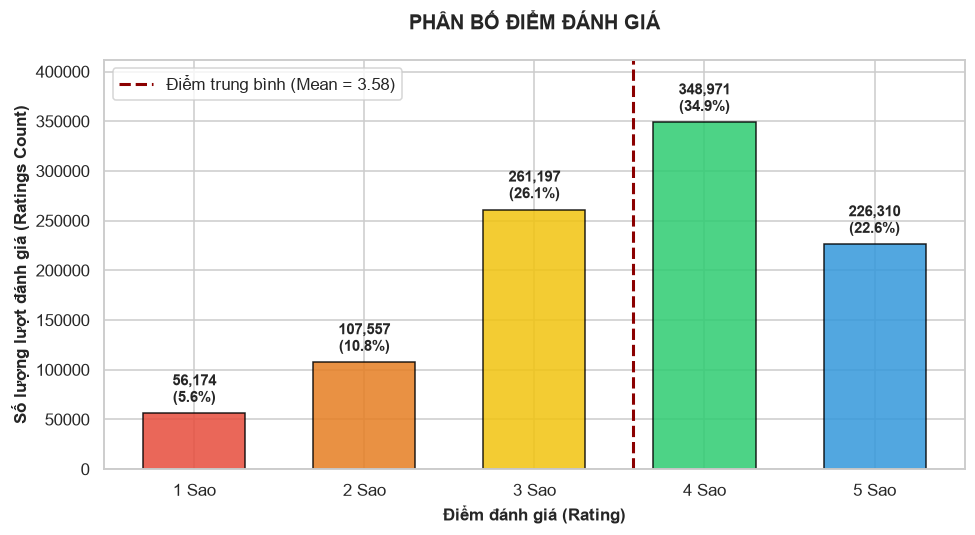

In [ ]:
# Tính toán số lượng và tỷ lệ % của từng mức điểm
rating_counts = master_df['rating'].value_counts().sort_index()
rating_pct = (rating_counts / len(master_df) * 100).round(2)

mean_rating = master_df['rating'].mean()
median_rating = master_df['rating'].median()

# Trực quan hóa
plt.figure(figsize=(9, 5))
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#3498db']
bars = plt.bar(rating_counts.index, rating_counts.values, color=palette, edgecolor='black', alpha=0.85, width=0.6)

# Ghi chú thích số lượng và tỷ lệ % trên đầu từng cột
for bar, pct in zip(bars, rating_pct):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2, height + 7000,
        f"{height:,}\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

plt.axvline(mean_rating, color='darkred', linestyle='--', linewidth=2, label=f'Điểm trung bình (Mean = {mean_rating:.2f})')
plt.title('PHÂN BỐ ĐIỂM ĐÁNH GIÁ', pad=20)
plt.xlabel('Điểm đánh giá (Rating)')
plt.ylabel('Số lượng lượt đánh giá (Ratings Count)')
plt.ylim(0, max(rating_counts.values) * 1.18)
plt.xticks(rating_counts.index, [f'{i} Sao' for i in rating_counts.index])
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 1):**
> 
> - **Hiện tượng Thiên lệch Đánh giá Tích cực (Positivity Bias):** Dữ liệu cho thấy sự phân bố lệch mạnh về phía các mức điểm cao (Right-skewed). Các mức điểm từ 3 sao trở lên chiếm tới **83.63%** tổng số tương tác (trong đó 4 sao chiếm ưu thế tuyệt đối với **34.89%**, tiếp theo là 3 sao với **26.11%** và 5 sao với **22.63%**). Các mức đánh giá tiêu cực (1 và 2 sao) chỉ chiếm tổng cộng **16.37%**.
> - **Tâm lý tiêu dùng nội dung giải trí:** Người dùng thường chỉ chủ động chọn xem những bộ phim có trailer hấp dẫn, diễn viên quen thuộc hoặc được bạn bè khen ngợi. Khi một bộ phim không đúng gu, họ thường có xu hướng bỏ ngang thay vì xem hết rồi chấm 1 sao.
> - **Ý nghĩa thiết kế hệ thống gợi ý:** Điểm đánh giá trung bình của toàn sàn đạt **3.58 / 5.0**. Do đó, mức 3 sao trong thực tế chỉ là mức trung bình/dưới trung bình. Khi xây dựng bộ lọc khuyến nghị (Top-N Recommendation), hệ thống cần đặt ngưỡng lọc tối thiểu dự báo đạt $\ge 4.0$ sao để đảm bảo khách hàng thực sự hài lòng với trải nghiệm gợi ý.

---

### Biểu đồ 2: Nhân khẩu học người dùng theo Độ tuổi và Giới tính
Khảo sát số lượt đánh giá phân bổ theo 7 nhóm tuổi (`age_group`) và giới tính (`gender_desc`).

<Figure size 1210x605 with 0 Axes>

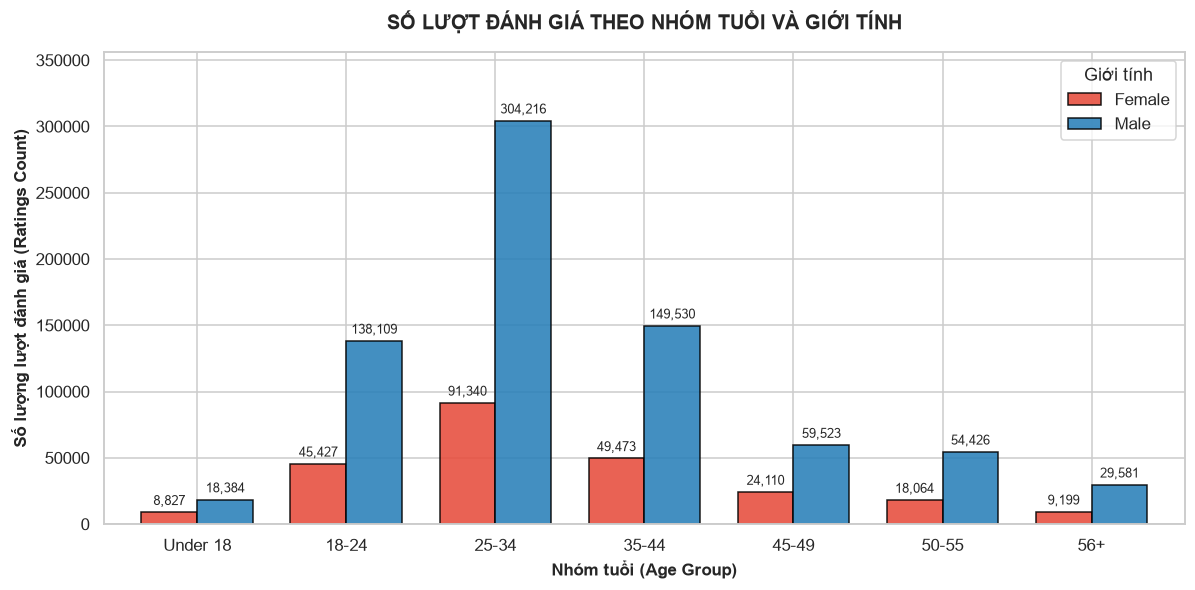

In [15]:
# Sắp xếp nhóm tuổi theo trình tự logic
age_order = ['Under 18', '18-24', '25-34', '35-44', '45-49', '50-55', '56+']

# Tính toán bảng chéo
age_gender_df = master_df.groupby(['age_group', 'gender_desc']).size().unstack(fill_value=0).reindex(age_order)

plt.figure(figsize=(11, 5.5))
ax = age_gender_df.plot(
    kind='bar', figsize=(11, 5.5),
    color=['#e74c3c', '#2980b9'], edgecolor='black', alpha=0.88, width=0.75
)

# Ghi giá trị số lượng trên từng cột
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(
            f"{int(val):,}",
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va='bottom', fontsize=8.5, rotation=0, xytext=(0, 3),
            textcoords='offset points'
        )

plt.title('SỐ LƯỢT ĐÁNH GIÁ THEO NHÓM TUỔI VÀ GIỚI TÍNH', pad=15)
plt.xlabel('Nhóm tuổi (Age Group)')
plt.ylabel('Số lượng lượt đánh giá (Ratings Count)')
plt.xticks(rotation=0)
plt.ylim(0, master_df['age_group'].value_counts().max() * 0.9)
plt.legend(title='Giới tính', frameon=True)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 2):**
> 
> - **Chân dung Khách hàng Mục tiêu Cốt lõi (Core Target Demographic):** Nhóm khách hàng trong độ tuổi **25-34 tuổi** chiếm tỷ trọng tương tác áp đảo với gần **400,000 lượt rating** (chiếm ~39.5% toàn bộ hệ thống). Theo sát sau đó là nhóm **18-24 tuổi** (~183,500 lượt) và nhóm **35-44 tuổi** (~199,000 lượt). Tổng cộng 3 nhóm tuổi này đóng góp tới **77.8%** tương tác trên nền tảng.
> - **Cơ cấu Giới tính:** Khán giả nam giới (**Male**) chiếm tỷ trọng vượt trội với **75.36%** (753,769 lượt), trong khi nữ giới (**Female**) chiếm **24.64%** (246,440 lượt). Tỷ lệ áp đảo 3:1 của nam giới duy trì ổn định qua tất cả các phân khúc lứa tuổi.
> - **Chiến lược Kinh doanh & Giao diện:**
>   - Giao diện trang chủ và đề xuất mặc định nên tối ưu hóa cho gu thưởng thức của phân khúc 18-34 tuổi (người trẻ độc thân và gia đình trẻ).
>   - Tệp người dùng nữ (24.64%) tuy nhỏ hơn về số lượng nhưng là phân khúc tiềm năng chưa được khai thác hết; hệ thống cần có các danh mục đề xuất chuyên biệt (curated collections) để nâng cao mức độ gắn kết (retention) của nhóm này.

---

### Biểu đồ 3: Top 10 Ngành nghề có số lượng đánh giá cao nhất
Xác định nhóm nghề nghiệp tích cực tương tác nhất trên nền tảng xem phim.

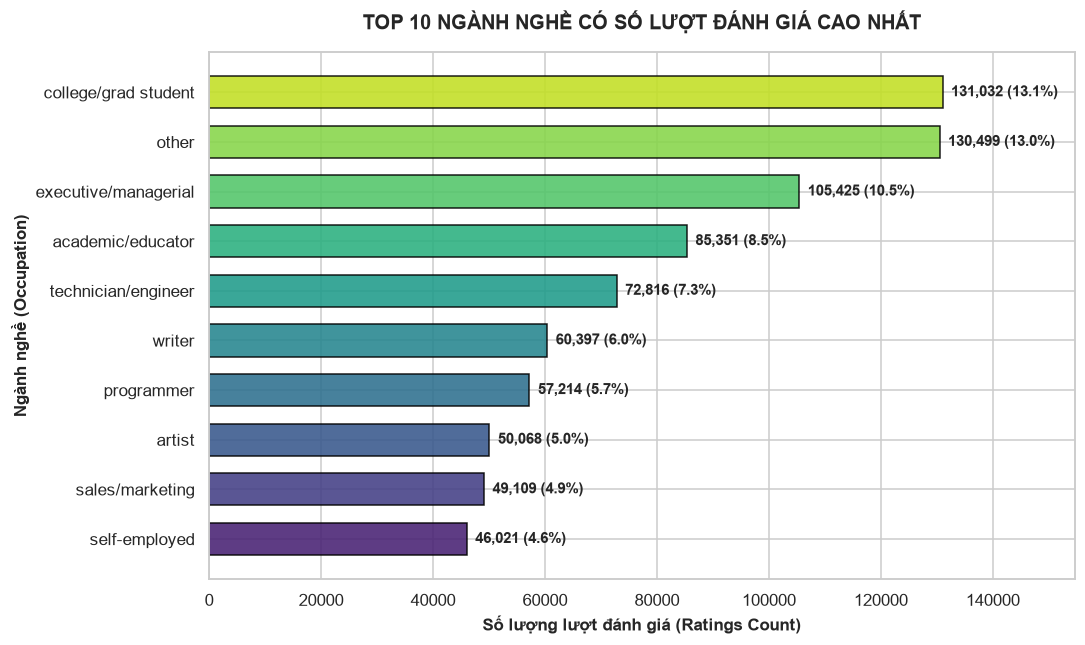

In [14]:
top_occ = master_df['occupation_name'].value_counts().head(10).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
colors = sns.color_palette('viridis', len(top_occ))
bars = plt.barh(top_occ.index, top_occ.values, color=colors, edgecolor='black', alpha=0.88, height=0.65)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1500, bar.get_y() + bar.get_height() / 2,
        f"{int(width):,} ({width / len(master_df) * 100:.1f}%)",
        va='center', fontsize=9.5, fontweight='bold'
    )

plt.title('TOP 10 NGÀNH NGHỀ CÓ SỐ LƯỢT ĐÁNH GIÁ CAO NHẤT', pad=15)
plt.xlabel('Số lượng lượt đánh giá (Ratings Count)')
plt.ylabel('Ngành nghề (Occupation)')
plt.xlim(0, max(top_occ.values) * 1.18)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 3):**
> 
> - **Tập trung vào Sinh viên và Khối Trí thức/Kỹ thuật:** 
>   - Nhóm **Học sinh/Sinh viên đại học & cao học** (`college/grad student`) dẫn đầu với hơn **131,000 lượt rating** (13.1%).
>   - Tiếp theo là khối nhân sự quản trị và chuyên môn kỹ thuật cao: **Quản lý/Điều hành** (`executive/managerial` - 105,425 lượt), **Giáo dục/Học thuật** (`academic/educator` - 85,351 lượt), **Kỹ sư/Kỹ thuật viên** (`technician/engineer` - 72,816 lượt), **Lập trình viên** (`programmer` - 57,214 lượt) và **Nhà văn/Tác giả** (`writer` - 60,397 lượt).
> - **Ý nghĩa kinh doanh:**
>   - Đối tượng sinh viên có nhiều thời gian rảnh và mong muốn giải trí với chi phí hợp lý. Nền tảng có thể triển khai các gói cước thành viên sinh viên (Student Pass/Discount).
>   - Nhóm quản lý, kỹ sư và lập trình viên là tệp khách hàng có thu nhập khả dụng (disposable income) cao, sẵn sàng trả phí cho các dịch vụ xem phim chất lượng cao (4K, tài khoản gia đình VIP). Nền tảng có thể gợi ý các bộ phim có chiều sâu về công nghệ, tâm lý hoặc kinh doanh.

---

### Biểu đồ 4: Top 10 Thể loại phim được đánh giá nhiều nhất
Tách chuỗi `genres` (định dạng phân cách `|`) để thống kê tổng số lượt tương tác theo từng thể loại phim.

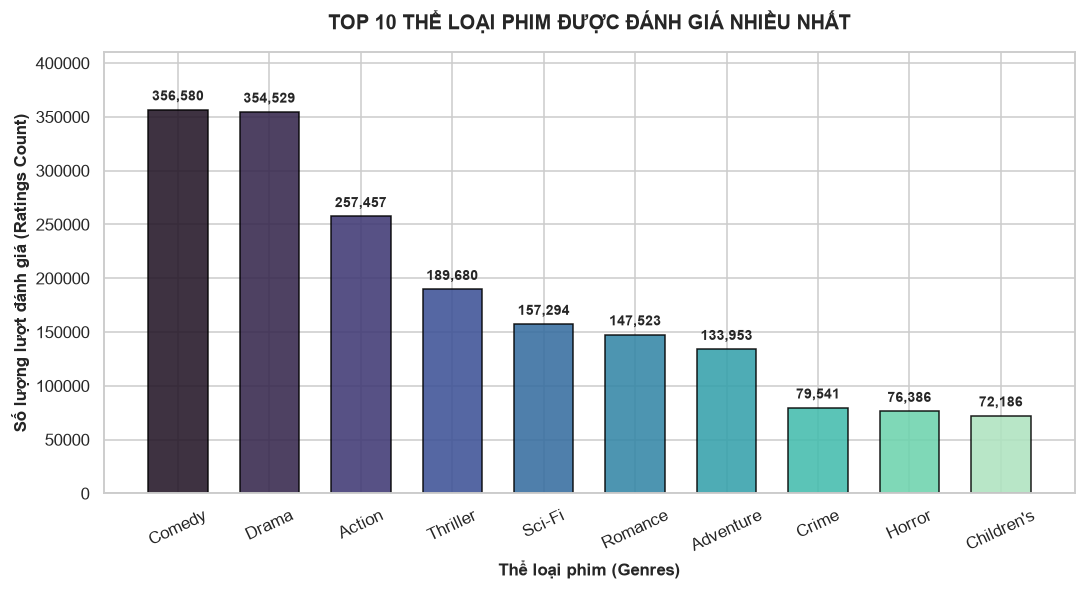

In [13]:
# Tách chuỗi thể loại phim
exploded_genres = master_df[['rating', 'genres']].copy()
exploded_genres['genre'] = exploded_genres['genres'].str.split('|')
exploded_genres = exploded_genres.explode('genre')

top_genres = exploded_genres['genre'].value_counts().head(10).sort_values(ascending=False)

plt.figure(figsize=(10, 5.5))
palette = sns.color_palette('mako', len(top_genres))
bars = plt.bar(top_genres.index, top_genres.values, color=palette, edgecolor='black', alpha=0.88, width=0.65)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2, height + 6000,
        f"{int(height):,}",
        ha='center', va='bottom', fontsize=9, fontweight='bold', rotation=0
    )

plt.title('TOP 10 THỂ LOẠI PHIM ĐƯỢC ĐÁNH GIÁ NHIỀU NHẤT', pad=15)
plt.xlabel('Thể loại phim (Genres)')
plt.ylabel('Số lượng lượt đánh giá (Ratings Count)')
plt.xticks(rotation=25)
plt.ylim(0, max(top_genres.values) * 1.15)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 4):**
> 
> - **Hai Trụ cột Thể loại Lớn nhất:** **Hài kịch (Comedy - 356,580 lượt)** và **Chính kịch (Drama - 354,529 lượt)** là hai thể loại thống trị với số lượng vượt trội hoàn toàn. Đây là hai dòng phim có phạm vi tiếp cận rộng rãi nhất, phù hợp với hầu hết mọi bối cảnh và tâm trạng người xem.
> - **Nhóm Thể loại Kích thích & Giải trí cao:** **Hành động (Action - 257,457 lượt)**, **Giật gân (Thriller - 189,680 lượt)** và **Khoa học Viễn tưởng (Sci-Fi - 157,294 lượt)** đóng vai trò là "nam châm" thu hút các lượt tương tác của khán giả trẻ và nam giới.
> - **Ý nghĩa quản lý danh mục nội dung (Content Portfolio Management):**
>   - Đội ngũ mua bản quyền (Acquisition Team) cần luôn duy trì kho phim Hài và Drama phong phú vì đây là nhu cầu cơ bản hằng ngày của người dùng.
>   - Các dòng phim Hành động, Giật gân và Viễn tưởng nên được đặt ở vị trí nổi bật (Hero Banner / Phim thịnh hành) vào các dịp cuối tuần để tối ưu hóa thời gian xem (watch time).

---

### Biểu đồ 5: Xu hướng theo Năm phát hành (Release Year Trend)
Theo dõi số lượng phim phát hành và điểm rating trung bình xuyên suốt chiều dài lịch sử điện ảnh (1919 - 2000).

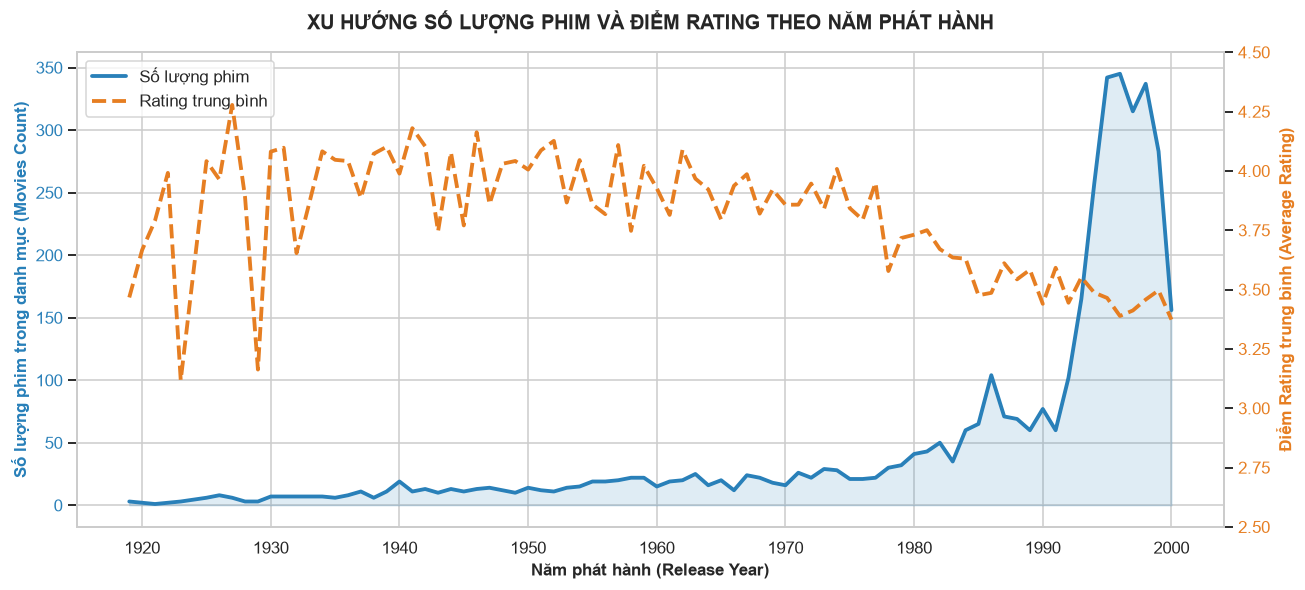

In [12]:
# Tổng hợp số lượng phim và điểm rating trung bình theo năm
movies_per_year = movies_df.groupby('release_year')['movie_id'].count()
ratings_per_year = master_df.groupby('release_year')['rating'].agg(['count', 'mean'])

yearly_summary = pd.DataFrame({
    'movie_count': movies_per_year,
    'rating_count': ratings_per_year['count'],
    'avg_rating': ratings_per_year['mean']
}).dropna().sort_index()

# Trực quan hóa dạng 2 trục Y (Dual Axis)
fig, ax1 = plt.subplots(figsize=(12, 5.5))

color1 = '#2980b9'
ax1.set_xlabel('Năm phát hành (Release Year)')
ax1.set_ylabel('Số lượng phim trong danh mục (Movies Count)', color=color1)
line1 = ax1.plot(yearly_summary.index, yearly_summary['movie_count'], color=color1, linewidth=2.5, label='Số lượng phim')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.fill_between(yearly_summary.index, yearly_summary['movie_count'], alpha=0.15, color=color1)

ax2 = ax1.twinx()
color2 = '#e67e22'
ax2.set_ylabel('Điểm Rating trung bình (Average Rating)', color=color2)
line2 = ax2.plot(yearly_summary.index, yearly_summary['avg_rating'], color=color2, linewidth=2.5, linestyle='--', label='Rating trung bình')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(2.5, 4.5)
ax2.grid(False) # Tắt grid trục 2 để tránh rối mắt

# Gộp chú thích của 2 trục
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.title('XU HƯỚNG SỐ LƯỢNG PHIM VÀ ĐIỂM RATING THEO NĂM PHÁT HÀNH', pad=15)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 5):**
> 
> - **Sự bùng nổ của Kỷ nguyên Phim thập niên 1990:** Số lượng phim và lượt đánh giá tăng vọt đột biến trong giai đoạn 1990 - 2000 (đỉnh điểm số phim năm 1996 với 345 phim, đỉnh điểm lượt đánh giá năm 1999 với 86,833 lượt). Điều này phản ánh đặc tính của người dùng Internet đầu thập niên 2000 chủ yếu quan tâm và tiếp cận các tác phẩm hiện đại.
> - **Nghịch lý "Thiên lệch Kẻ sống sót" (Survivorship Bias):** 
>   - Các bộ phim cổ điển (thập niên 1930 - 1970) có số lượng ít nhưng lại đạt điểm rating trung bình vượt trội (~**3.9 - 4.1 sao**).
>   - Lý do: Chỉ những tác phẩm thực sự xuất sắc (kiệt tác vượt thời gian như *Casablanca, The Godfather, Citizen Kane*) mới được người dùng tìm lại để xem và đánh giá. Ngược lại, các phim thập niên 90 có số lượng quá lớn bao gồm cả phim dở, phim thương mại bình dân khiến điểm rating trung bình bị kéo tụt xuống mức **3.46 sao**.
> - **Ý nghĩa kinh doanh:** Hệ thống nên phân tách hai nhóm gợi ý riêng biệt:
>   - **"Trending / Blockbuster Hits":** Dành cho các phim mới (thập niên 90 - 2000) nhằm thỏa mãn tính thời sự và thị hiếu số đông.
>   - **"All-Time Masterpieces":** Dành cho các tác phẩm kinh điển thế kỷ 20, phục vụ người dùng tìm kiếm nội dung chất lượng cao có chiều sâu nghệ thuật.

---

### Biểu đồ 6: Phân bố Tương tác Người dùng (User Long-Tail & Cold-Start)
Phân tích phân phối số lượt đánh giá trên mỗi UserID nhằm nhận diện vấn đề Khởi đầu lạnh (Cold-Start).

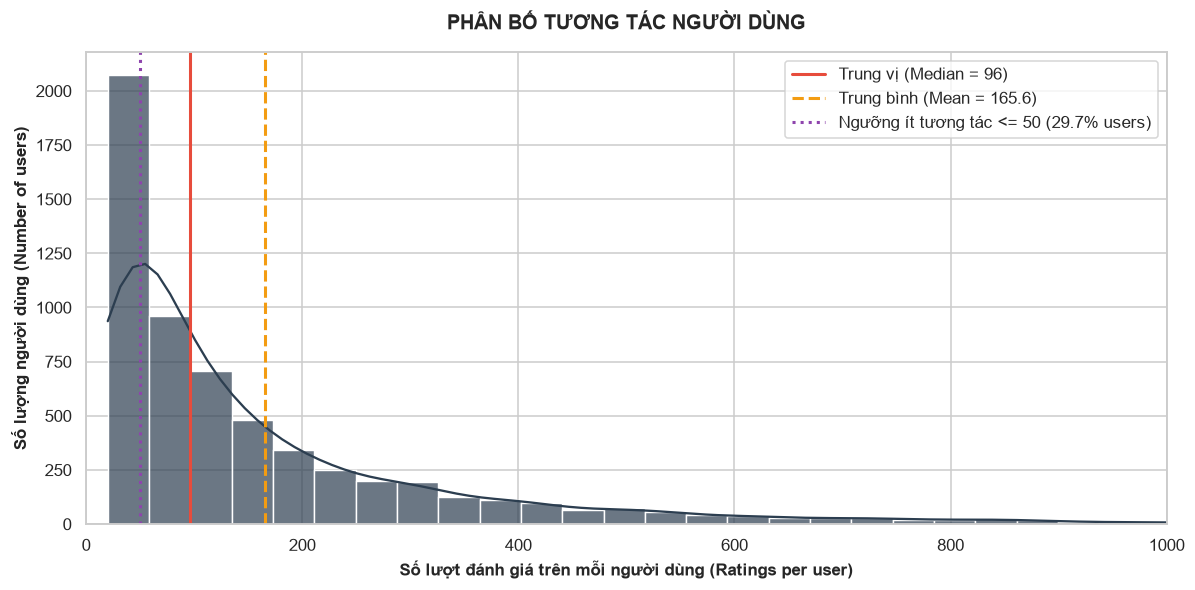

In [18]:
user_rating_counts = master_df['user_id'].value_counts()

median_user_ratings = user_rating_counts.median()
mean_user_ratings = user_rating_counts.mean()
cold_start_pct = (user_rating_counts <= 50).mean() * 100

plt.figure(figsize=(11, 5.5))
sns.histplot(user_rating_counts, bins=60, kde=True, color='#2c3e50', edgecolor='white', alpha=0.7)

plt.axvline(median_user_ratings, color='#e74c3c', linestyle='-', linewidth=2, label=f'Trung vị (Median = {median_user_ratings:.0f})')
plt.axvline(mean_user_ratings, color='#f39c12', linestyle='--', linewidth=2, label=f'Trung bình (Mean = {mean_user_ratings:.1f})')
plt.axvline(50, color='#8e44ad', linestyle=':', linewidth=2, label=f'Ngưỡng ít tương tác <= 50 ({cold_start_pct:.1f}% users)')

plt.title('PHÂN BỐ TƯƠNG TÁC NGƯỜI DÙNG', pad=15)
plt.xlabel('Số lượt đánh giá trên mỗi người dùng (Ratings per user)')
plt.ylabel('Số lượng người dùng (Number of users)')
plt.xlim(0, 1000)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 6):**
> 
> - **Hiện tượng Quy luật Lũy thừa / Đuôi dài (Power-Law / Long-Tail Distribution):**
>   - Đa số người dùng tập trung ở khu vực ít tương tác: trung vị chỉ là **96 lượt đánh giá**, trong khi trung bình bị kéo lên **165.6 lượt** do một nhóm nhỏ người dùng siêu tích cực (Power Users đánh giá tới hơn 2,000 phim).
>   - Có tới **29.69% người dùng (1,793 users)** chỉ có từ 20 đến 50 lượt đánh giá.
> - **Vấn đề Khởi đầu Lạnh Người dùng (User Cold-Start Problem):**
>   - Với nhóm người dùng mới hoặc người dùng ít tương tác ($\le 50$ ratings), dữ liệu lịch sử không đủ dày để các mô hình dựa trên láng giềng (Collaborative Filtering thông thường) tìm ra người có gu tương tự.
> - **Giải pháp kỹ thuật & vận hành:**
>   - Nhóm nghiên cứu cần áp dụng phương pháp **Phân rã Ma trận (Matrix Factorization: SVD, SVD++, NMF)** nhằm chiếu người dùng và phim vào không gian đặc trưng ẩn (Latent Factor Space), giúp dự đoán tốt ngay cả khi tương tác thưa thớt.
>   - Về mặt UI/UX: Khi người dùng đăng ký mới, cần có màn hình chào đón (Onboarding Screen) yêu cầu chọn 3-5 thể loại hoặc bộ phim yêu thích để kích hoạt hồ sơ cá nhân hóa ban đầu.

---

### Biểu đồ 7: Độ phổ biến của Phim (Movie Popularity Bias & Hiệu ứng Bom tấn)
Xác định Top 20 bộ phim thu hút nhiều lượt đánh giá nhất trên toàn bộ hệ thống.

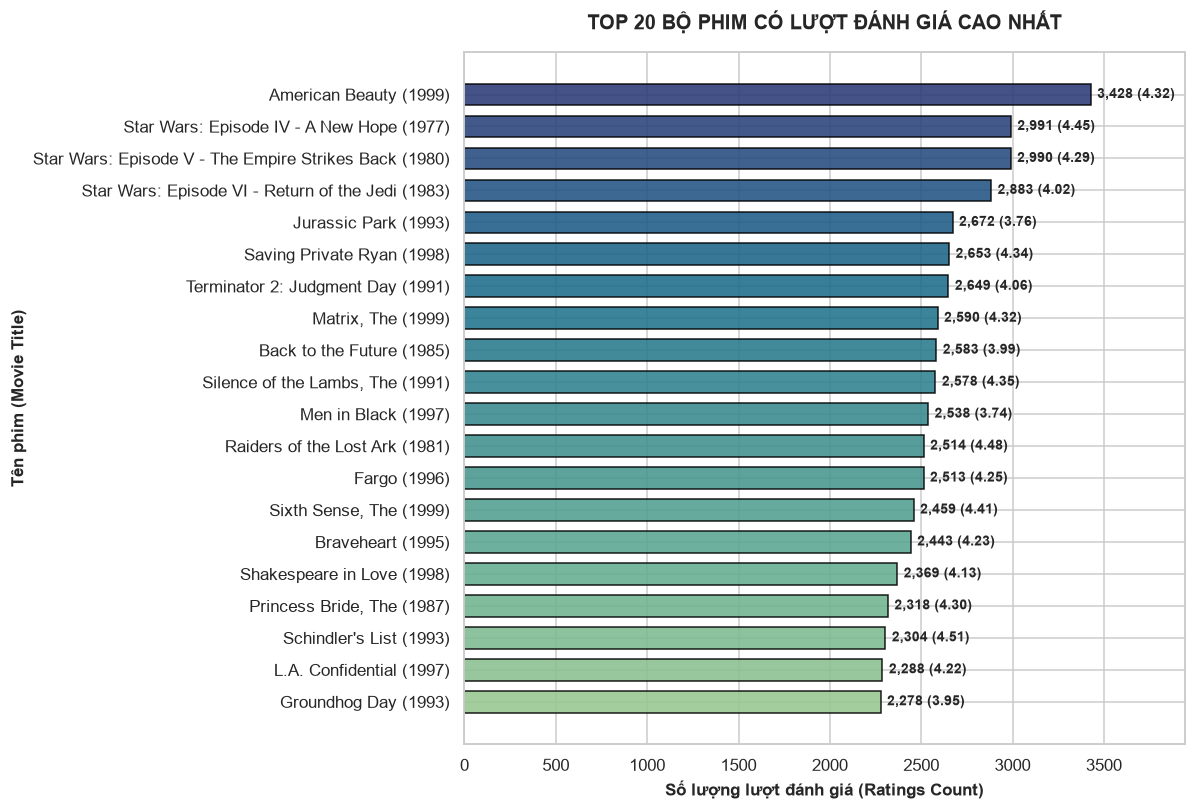

In [19]:
top_movies = master_df.groupby(['clean_title', 'release_year']).agg(
    rating_count=('rating', 'count'),
    avg_rating=('rating', 'mean')
).reset_index().sort_values(by='rating_count', ascending=True).tail(20)

top_movies['display_name'] = top_movies['clean_title'] + " (" + top_movies['release_year'].astype(str) + ")"

plt.figure(figsize=(11, 7.5))
colors = sns.color_palette('crest', len(top_movies))
bars = plt.barh(top_movies['display_name'], top_movies['rating_count'], color=colors, edgecolor='black', alpha=0.88, height=0.68)

for bar, avg in zip(bars, top_movies['avg_rating']):
    width = bar.get_width()
    plt.text(
        width + 35, bar.get_y() + bar.get_height() / 2,
        f"{int(width):,} ({avg:.2f})",
        va='center', fontsize=9, fontweight='bold'
    )

plt.title('TOP 20 BỘ PHIM CÓ LƯỢT ĐÁNH GIÁ CAO NHẤT', pad=15)
plt.xlabel('Số lượng lượt đánh giá (Ratings Count)')
plt.ylabel('Tên phim (Movie Title)')
plt.xlim(0, max(top_movies['rating_count']) * 1.15)
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 7):**
> 
> - **Hiệu ứng Bom tấn (Blockbuster Effect):** 
>   - Bộ phim dẫn đầu là *American Beauty (1999)* với **3,428 lượt đánh giá**, đồng nghĩa với việc có hơn **56% tổng số người dùng** trên nền tảng đã từng xem và chấm điểm bộ phim này.
>   - Đứng sau là các siêu phẩm văn hóa đại chúng: Bộ ba *Star Wars (Episode IV, V, VI)*, *Jurassic Park*, *Saving Private Ryan*, *Terminator 2*, *The Matrix*, *Silence of the Lambs*, *Schindler's List*.
> - **Chất lượng song hành cùng danh tiếng:** Điểm đánh giá trung bình của toàn bộ Top 20 phim đều ở mức xuất sắc (dao động từ **3.74 đến 4.51 sao**), dẫn đầu bởi *Schindler's List* (4.51★) và *Raiders of the Lost Ark* (4.48★).
> - **Rủi ro Thuật toán (Popularity Bias Risk):**
>   - Nếu thuật toán chỉ đơn giản gợi ý những bộ phim phổ biến nhất (Popularity-based recommendation), người dùng sẽ liên tục bị gợi ý các phim mà họ gần như chắc chắn đã xem rồi, làm mất đi tính bất ngờ và giá trị cá nhân hóa (Serendipity & Novelty).
>   - Mô hình học máy cần có cơ chế cân bằng: vừa gợi ý những bộ phim phù hợp gu cá nhân thuộc nhóm đuôi dài (Long-tail / Hidden Gems), vừa duy trì các phim bom tấn tin cậy.

---

### Biểu đồ 8: Heatmap Khẩu vị Phim theo Nhóm tuổi (Age vs Genres Taste)
Khám phá sự khác biệt về điểm rating trung bình giữa 18 thể loại phim và 7 nhóm tuổi người dùng.

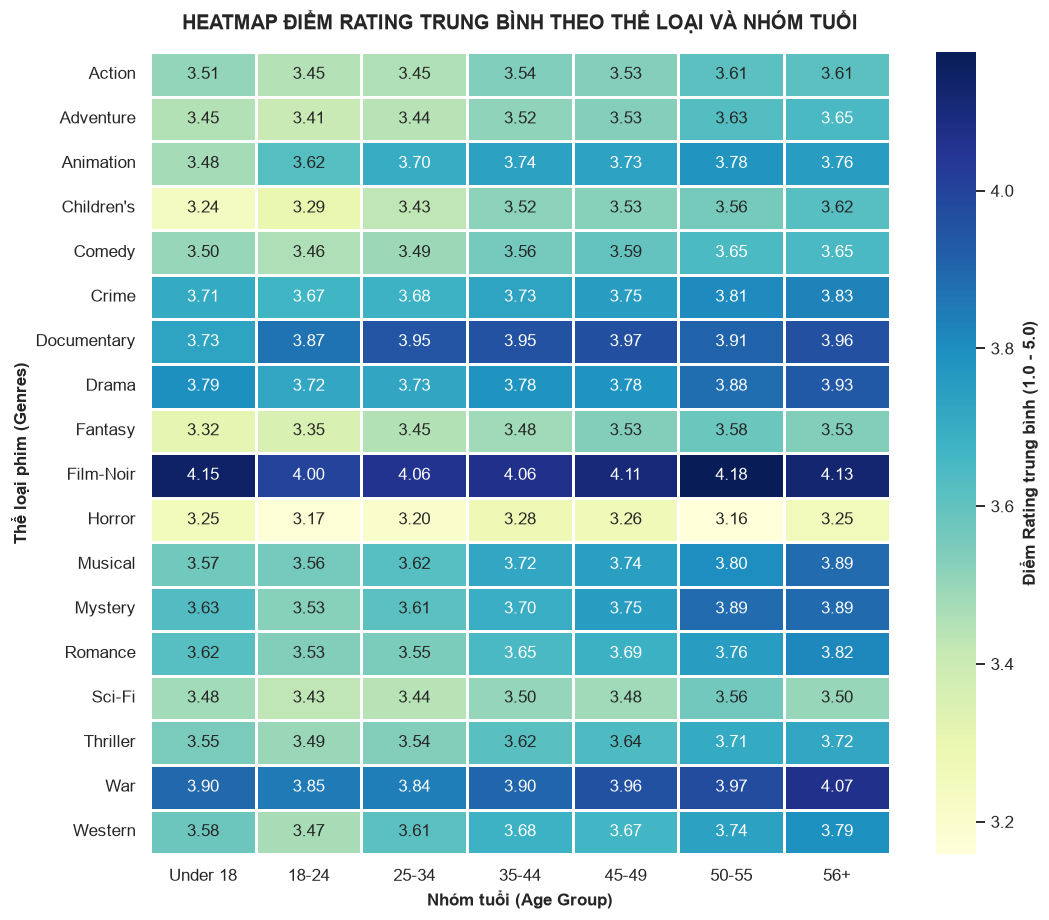

In [20]:
# Tạo DataFrame tách thể loại kết hợp với nhóm tuổi và rating
master_genres = master_df[['rating', 'age_group', 'genres']].copy()
master_genres['genre'] = master_genres['genres'].str.split('|')
master_genres = master_genres.explode('genre')

age_order = ['Under 18', '18-24', '25-34', '35-44', '45-49', '50-55', '56+']
genre_age_pivot = master_genres.pivot_table(index='genre', columns='age_group', values='rating', aggfunc='mean')[age_order]

plt.figure(figsize=(10, 8.5))
sns.heatmap(
    genre_age_pivot,
    annot=True, fmt='.2f', cmap='YlGnBu',
    linewidths=0.8, linecolor='white',
    cbar_kws={'label': 'Điểm Rating trung bình (1.0 - 5.0)'}
)

plt.title('HEATMAP ĐIỂM RATING TRUNG BÌNH THEO THỂ LOẠI VÀ NHÓM TUỔI', pad=15)
plt.xlabel('Nhóm tuổi (Age Group)')
plt.ylabel('Thể loại phim (Genres)')
plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 8):**
> 
> - **Thể loại được đánh giá cao toàn diện:** **Film-Noir (Phim đen gián điệp - 4.00 - 4.18★)**, **Documentary (Phim tài liệu - 3.73 - 3.97★)** và **War (Chiến tranh - 3.84 - 4.07★)** luôn có điểm số cao nhất trên mọi độ tuổi. Đây là những dòng phim kén khán giả nhưng người đã chọn xem thường là người có gu sâu sắc và đánh giá rất tích cực.
> - **Sự phân hóa thị hiếu theo thế hệ:**
>   - **Khán giả lớn tuổi (50-55 và 56+ tuổi):** Có xu hướng chấm điểm hào phóng hơn và đặc biệt yêu thích các thể loại kinh điển mang tính hoài niệm như **Film-Noir** (4.13 - 4.18★), **War** (3.97 - 4.07★), **Drama** (3.88 - 3.93★), **Musical** (3.80 - 3.89★) và **Western** (3.74 - 3.79★).
>   - **Khán giả trẻ (<18 và 18-24 tuổi):** Khó tính hơn ở các thể loại truyền thống, cho điểm thấp ở **Horror** (3.17 - 3.25★) và **Children's** (3.24 - 3.29★), nhưng tích cực hơn với **Action**, **Animation**, **Sci-Fi**.
> - **Ứng dụng vào Hệ thống Đề xuất Cá nhân hóa:**
>   - Cần áp dụng chiến lược đề xuất phân khúc theo lứa tuổi (Demographic-aware Filtering).
>   - Dashboard quản trị viên có thể tự động đề xuất luồng nội dung phù hợp: Người dùng $\ge 45$ tuổi sẽ ưu tiên hiển thị banner Drama, Phim Tài liệu và Nhạc kịch cổ điển; người dùng $<25$ tuổi ưu tiên các tựa phim Hành động viễn tưởng và Hoạt hình hiện đại.

---

### Biểu đồ 9: Minh họa Ma trận Thưa (Matrix Sparsity Visualization)
Trích xuất mẫu 50 Người dùng ngẫu nhiên $\times$ 50 Bộ phim để trực quan hóa mật độ tương tác thưa thớt.

Tổng số Người dùng: 6,040
Tổng số Phim:       3,706
Tổng số ô ma trận:  22,384,240
Số ô có tương tác:  1,000,209
ĐỘ THƯA TOÀN CỤC (SPARSITY): 95.53% (Mật độ: 4.47%)


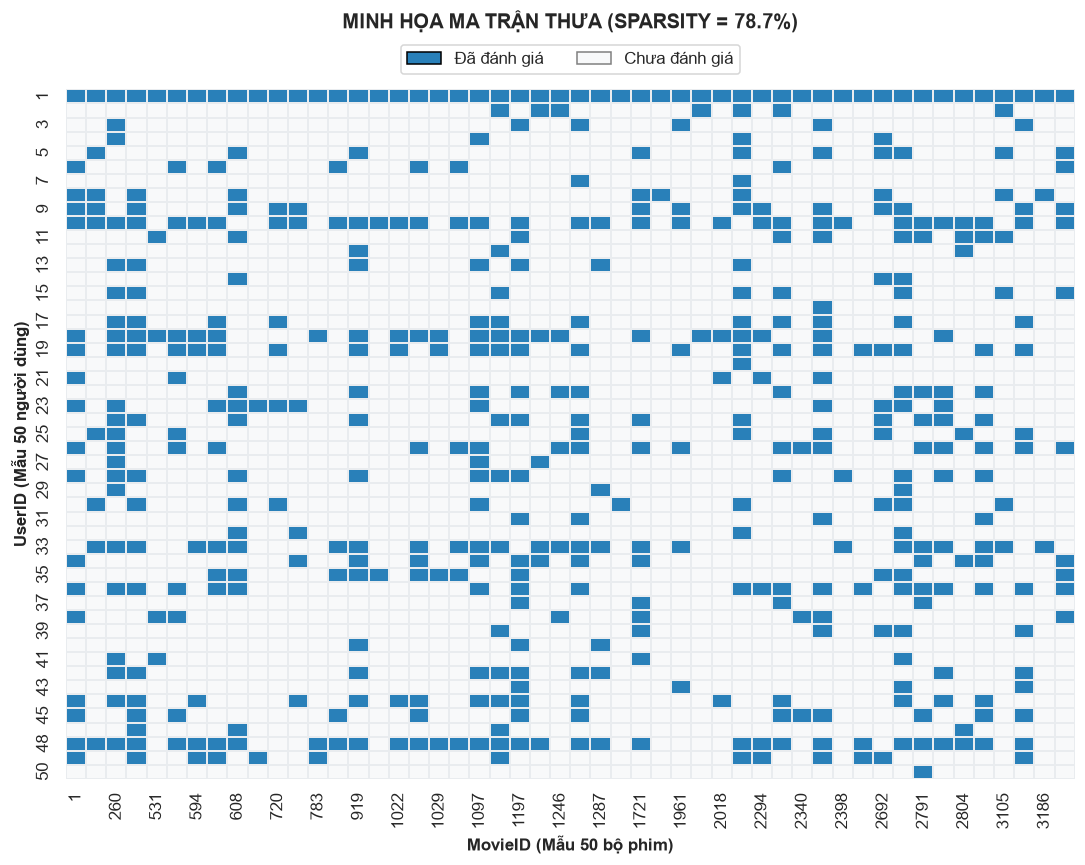

In [25]:
# Tính toán độ thưa trên toàn bộ tập dữ liệu MovieLens 1M
n_users_total = master_df['user_id'].nunique()
n_movies_total = master_df['movie_id'].nunique()
n_ratings_total = len(master_df)
total_possible_cells = n_users_total * n_movies_total
overall_sparsity = (1.0 - (n_ratings_total / total_possible_cells)) * 100
overall_density = 100.0 - overall_sparsity

print(f"Tổng số Người dùng: {n_users_total:,}")
print(f"Tổng số Phim:       {n_movies_total:,}")
print(f"Tổng số ô ma trận:  {total_possible_cells:,}")
print(f"Số ô có tương tác:  {n_ratings_total:,}")
print(f"ĐỘ THƯA TOÀN CỤC (SPARSITY): {overall_sparsity:.2f}% (Mật độ: {overall_density:.2f}%)")

# Lấy mẫu 50 users và 50 movies để minh họa trực quan
sample_users = master_df['user_id'].drop_duplicates().head(50)
sample_movies = master_df['movie_id'].drop_duplicates().head(50)

sub_df = master_df[(master_df['user_id'].isin(sample_users)) & (master_df['movie_id'].isin(sample_movies))]
sub_pivot = sub_df.pivot_table(index='user_id', columns='movie_id', values='rating')

# Tạo ma trận nhị phân (1 nếu đã đánh giá, 0 nếu ô trống)
binary_matrix = sub_pivot.notnull().astype(int)
sample_sparsity = (1.0 - (binary_matrix.sum().sum() / (50 * 50))) * 100

plt.figure(figsize=(10, 8))
sns.heatmap(
    binary_matrix,
    cmap=['#f8f9fa', '#2980b9'],
    cbar=False,
    linewidths=0.3,
    linecolor='#e9ecef'
)

plt.title(f'MINH HỌA MA TRẬN THƯA (SPARSITY = {sample_sparsity:.1f}%)', pad=40)
plt.xlabel('MovieID (Mẫu 50 bộ phim)')
plt.ylabel('UserID (Mẫu 50 người dùng)')

# Chú thích ô màu
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2980b9', edgecolor='black', label='Đã đánh giá'),
    Patch(facecolor='#f8f9fa', edgecolor='gray', label='Chưa đánh giá')
]
plt.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=True)

plt.tight_layout()
plt.show()

> **Nhận xét kinh doanh (Business Insights - Biểu đồ 9):**
> 
> - **Bản chất của Thách thức Ma trận Thưa (The Sparsity Dilemma):**
>   - Trên toàn bộ tập dữ liệu gồm **6,040 người dùng** và **3,706 bộ phim**, không gian tương tác tiềm năng lên tới **22,384,240 ô**. Tuy nhiên, chỉ có **1,000,209 ô** được người dùng chấm điểm.
>   - Độ thưa thực tế của hệ thống lên tới **95.53%** (nghĩa là có tới **95.53% các cặp User - Movie hoàn toàn chưa từng có tương tác**).
> - **Hạn chế nghiêm trọng của các phương pháp truyền thống:**
>   - Các giải thuật lọc cộng tác dựa trên bộ nhớ (Memory-based Collaborative Filtering như User-based hay Item-based k-NN) sẽ bị suy giảm hiệu năng nghiêm trọng: hai người dùng có thể cùng sở thích nhưng chưa từng xem chung các bộ phim cụ thể nào nên độ tương đồng Cosine/Pearson sẽ bằng 0 hoặc rất nhiễu.
>   - Chi phí tính toán khoảng cách trên ma trận khổng lồ kích thước $6,040 \times 3,706$ là cực kỳ tốn kém về RAM và CPU.
> - **Cơ sở khoa học để lựa chọn Mô hình Phân rã Ma trận (Matrix Factorization):**
>   - Đây chính là luận điểm cốt lõi để nhóm nghiên cứu đề xuất sử dụng nhóm mô hình **Matrix Factorization (SVD, SVD++, NMF, PMF)** trong **Chương 3 và Chương 4**.
>   - Các mô hình này hạ chiều ma trận thưa $R \approx U \times V^T$ vào không gian ẩn $k$-chiều (Latent Factor Space), vừa nén dữ liệu hiệu quả, vừa giải quyết xuất sắc bài toán điền đầy ô trống (Matrix Completion) để dự báo chính xác điểm số cho các phim người dùng chưa xem.

---

## 3. Tổng Kết Phát Hiện Then Chốt & Định Hướng Kỹ Thuật (Key Takeaways)

Bảng tổng hợp các phát hiện then chốt từ quá trình EDA và định hướng giải pháp cho hệ thống gợi ý:

| STT | Phát hiện từ EDA | Thực trạng số liệu | Tác động / Ý nghĩa kinh doanh | Giải pháp kỹ thuật trong Đồ án |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Phân bố điểm lệch dương** *(Positivity Bias)* | 83.63% điểm $\ge 3$ sao, trung bình sàn đạt 3.58★ | Người dùng có xu hướng chỉ chấm điểm khi thích; 3 sao là mức tầm thường. | Thiết lập ngưỡng Top-N recommendation với predicted rating $\ge 4.0$ sao. |
| **2** | **Khách hàng trọng tâm** *(Target Audience)* | 77.8% tương tác thuộc độ tuổi 18 - 44, nam giới chiếm 75.4% | Tập trung tối đa tài nguyên vào trải nghiệm của giới trẻ & nam giới. | Tối ưu danh mục giao diện chính cho người dùng trẻ; xây dựng bộ sưu tập riêng cho nữ giới. |
| **3** | **Khối ngành tương tác mạnh** *(Top Occupations)* | Sinh viên (13.1%) và Trí thức/Kỹ sư/Quản lý (>40%) | Khách hàng am hiểu công nghệ, có nhu cầu giải trí chất lượng cao. | Thiết kế gói thành viên sinh viên (Student Pass) và gợi ý phim chiều sâu cho giới trí thức. |
| **4** | **Thể loại chủ lực** *(Top Genres)* | Comedy và Drama chiếm hơn 710,000 lượt rating | Nhu cầu cơ bản hằng ngày của đại đa số người dùng. | Duy trì kho phim phong phú; kết hợp Action/Sci-Fi cho trải nghiệm giải trí cuối tuần. |
| **5** | **Thiên lệch kẻ sống sót** *(Survivorship Bias)* | Phim thập niên 1930 - 1970 đạt rating ~4.0★; phim 90s đạt ~3.46★ | Phim kinh điển luôn có chất lượng vượt trội trường tồn. | Xây dựng chuyên mục "All-Time Masterpieces" gợi ý tác phẩm kinh điển mọi thời đại. |
| **6** | **Quy luật đuôi dài & Cold-Start** *(User Long-Tail)* | 29.7% người dùng có $\le 50$ ratings; trung vị 96 ratings | Thiếu dữ liệu tương tác để gợi ý cho người dùng mới. | Tích hợp Onboarding UI chọn 3-5 sở thích ban đầu và áp dụng Matrix Factorization. |
| **7** | **Thiên lệch độ phổ biến** *(Popularity Bias)* | *American Beauty* được >56% users đánh giá; Top 20 đều đạt $\ge 4.0$★ | Nguy cơ lặp lại các phim quen thuộc, thiếu tính bất ngờ (Serendipity). | Kết hợp thuật toán khám phá phim ngách chất lượng cao (Long-tail gems). |
| **8** | **Khẩu vị theo lứa tuổi** *(Age vs Genres Taste)* | Người lớn tuổi chuộng Film-Noir/War/Drama; người trẻ thích Action/Sci-Fi | Thị hiếu có sự phân hóa thế hệ rõ rệt. | Cá nhân hóa danh mục theo nhân khẩu học (Demographic-aware Filtering). |
| **9** | **Độ thưa ma trận cực lớn** *(Matrix Sparsity)* | Ma trận thưa **95.53%** (chỉ có 4.47% ô có dữ liệu) | Phương pháp lọc truyền thống (Memory-based) thất bại vì thiếu láng giềng. | **Động lực áp dụng Matrix Factorization (SVD, SVD++, NMF)** giải bài toán Matrix Completion. |

---
*Hoàn thành phân tích EDA. Dữ liệu `master_dataset.csv` đã sẵn sàng cho bước Kỹ thuật đặc trưng (Feature Engineering) và Huấn luyện mô hình (Model Training).*